In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ustawienie stylu wykresów (będą dobrze wyglądać w sprawozdaniu)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Wczytanie zbioru danych (ścieżka względna z folderu notebooks/)
df = pd.read_csv("../data/tabular/healthcare-dataset-stroke-data.csv")

print(f"Wymiary zbioru: {df.shape[0]} wierszy, {df.shape[1]} kolumn")
display(df.head())

Wymiary zbioru: 5110 wierszy, 12 kolumn


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [2]:
print("--- Informacje o kolumnach i typach danych ---")
df.info()

print("\n--- Liczba brakujących wartości (NaN) ---")
missing = df.isnull().sum()
print(missing[missing > 0])

print(f"\nLiczba zduplikowanych wierszy: {df.duplicated().sum()}")

--- Informacje o kolumnach i typach danych ---
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB

--- Liczba brakujących wartości (NaN) ---
bmi    201
dtype: int64

Liczba zduplikowanych wierszy: 0


In [3]:
# Statystyki dla cech numerycznych (bez ID)
display(df.drop(columns=["id"]).describe().round(2))

# Rozkład wartości dla zmiennych tekstowych (kategorycznych)
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
for col in cat_cols:
    print(f"\n--- Rozkład kategorii: {col} ---")
    print(df[col].value_counts())

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,43.23,0.1,0.05,106.15,28.89,0.05
std,22.61,0.3,0.23,45.28,7.85,0.22
min,0.08,0.0,0.00,55.12,10.30,0.00
25%,25.00,0.0,0.00,77.24,23.50,0.00
50%,45.00,0.0,0.00,91.88,28.10,0.00
75%,61.00,0.0,0.00,114.09,33.10,0.00
max,82.00,1.0,1.00,271.74,97.60,1.00



--- Rozkład kategorii: gender ---
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

--- Rozkład kategorii: ever_married ---
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

--- Rozkład kategorii: work_type ---
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

--- Rozkład kategorii: Residence_type ---
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

--- Rozkład kategorii: smoking_status ---
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


C:\Users\Bartek\AppData\Local\Temp\ipykernel_1328\1339809505.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="stroke", ax=axes[0], palette="Set2")
C:\Users\Bartek\AppData\Local\Temp\ipykernel_1328\1339809505.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="stroke", y="avg_glucose_level", ax=axes[2], palette="Set2")


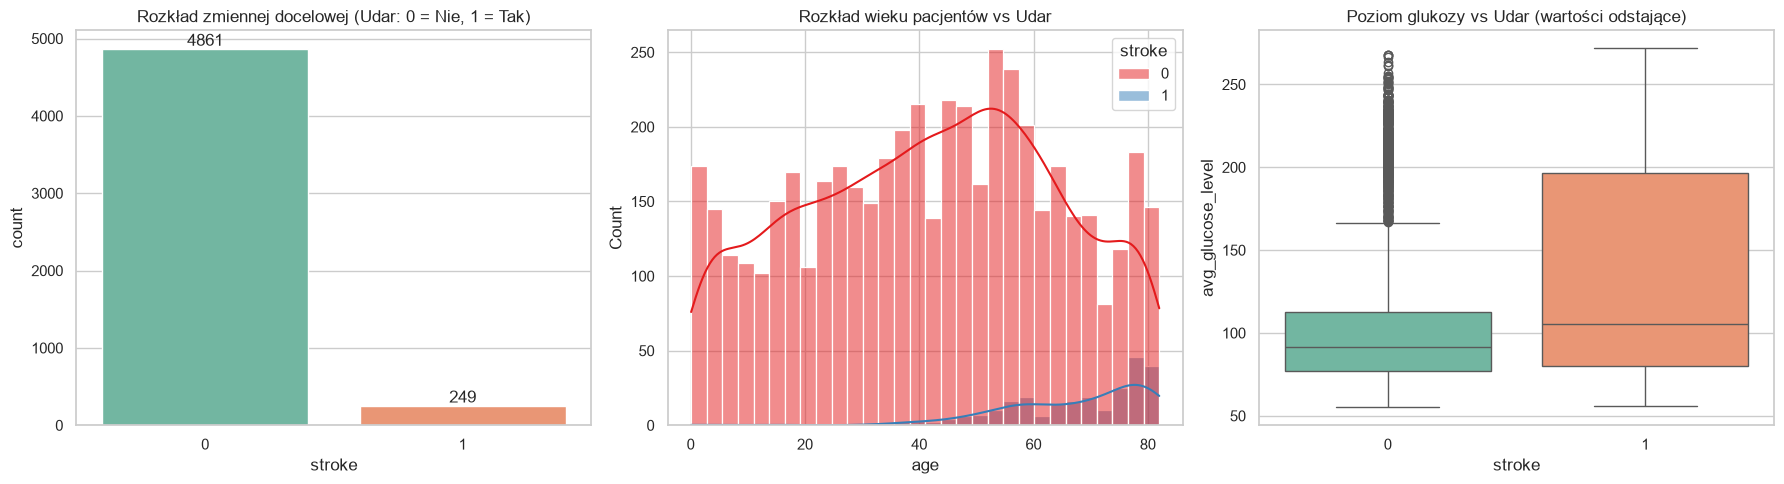

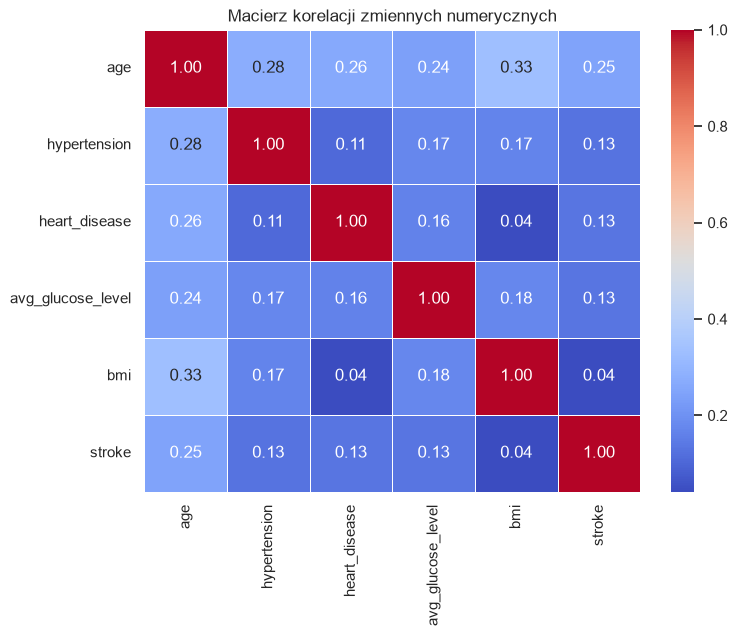

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Rozkład zmiennej docelowej (stroke)
sns.countplot(data=df, x="stroke", ax=axes[0], palette="Set2")
axes[0].set_title("Rozkład zmiennej docelowej (Udar: 0 = Nie, 1 = Tak)")
for container in axes[0].containers:
    axes[0].bar_label(container)

# 2. Rozkład wieku względem wystąpienia udaru
sns.histplot(data=df, x="age", hue="stroke", kde=True, bins=30, ax=axes[1], palette="Set1")
axes[1].set_title("Rozkład wieku pacjentów vs Udar")

# 3. Rozkład poziomu glukozy (wykres pudełkowy - wyłapuje wartości odstające)
sns.boxplot(data=df, x="stroke", y="avg_glucose_level", ax=axes[2], palette="Set2")
axes[2].set_title("Poziom glukozy vs Udar (wartości odstające)")

plt.tight_layout()
plt.show()

# 4. Macierz korelacji zmiennych numerycznych
plt.figure(figsize=(8, 6))
numeric_df = df.drop(columns=["id"]).select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Macierz korelacji zmiennych numerycznych")
plt.show()